# Kunz et al. 2025, inner speech in motor cortex: the source data

<img src="assets/experiment.png" alt="Graphical abstract of Kunz et al. 2025" width="560">

A tour of the **Dryad deposit** (`.mat` files), read through [`utils.py`](utils.py). The dataset probes the neural representation of **inner (imagined) speech** in four BrainGate2 participants (T12, T15, T16, T17) with severe dysarthria or anarthria, recorded with 64-channel Utah arrays in the left precentral gyrus and, for T12, the left inferior frontal gyrus.

**What each `.mat` file is.** The blocks of one task, for one participant on one day, concatenated with the unrecorded time between blocks removed. The two neural-feature matrices index a uniform bin grid, and the per-trial *delay* and *go* periods are stored as 1-based inclusive bin ranges into it.

**References.** Kunz et al. (2025) *Cell* 188, 4658-4673, [doi:10.1016/j.cell.2025.06.015](https://doi.org/10.1016/j.cell.2025.06.015). Dryad [doi:10.5061/dryad.gf1vhhn1j](https://datadryad.org/dataset/doi:10.5061/dryad.gf1vhhn1j). Code [nptl-stanford/inner_speech](https://github.com/nptl-stanford/inner_speech).

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio

from neuralshed.datasets.kunz_2025 import study, utils
from neuralshed.datasets.utils import dataset_dir

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 50)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("kunz_2025") / "data"
s = study.Kunz2025InnerSpeech(path=root)
s.download()

# the Study base appends the class-name folder
DATA = s.path

# one file per source branch
F_RAW = DATA / "isolatedVerbalBehaviors/t15.2024.04.07_allBehaviors_raw.mat"
F_CENTRED = DATA / "seqRecallSpeech/t16.2024.07.17_binnedTX_spikePow_20ms.mat"
F_TAGGED = (
    DATA
    / "seqRecallUninstructedSingleArrow/t12.2023.05.16_binnedTX_spikePow_20ms_joystickSingle.mat"
)
F_COPIED = (
    DATA
    / "interleavedVerbalBehaviors/t12.2024.04.11_interleavedVerbalBehaviors_raw.mat"
)
F_T16_SEQ = (
    DATA / "seqRecallVerbalMemory/t16.2024.07.17_binnedTX_spikePow_20ms_verbal.mat"
)


def block_table(path):
    # the continuously recorded blocks of one file
    table = pd.DataFrame(utils.block_segments(path))
    table["n_bins"] = table.stop_bin - table.start_bin
    return table


def stored_epochs(path):
    # the file's own delay and go epochs, 0-based [start, stop) bins
    mat = sio.loadmat(str(path), variable_names=["delayTrialEpochs", "goTrialEpochs"])
    delay = mat["delayTrialEpochs"].astype(int)
    go = mat["goTrialEpochs"].astype(int)
    return pd.DataFrame(
        {
            "delay_start": delay[:, 0] - 1,
            "delay_stop": delay[:, 1],
            "go_start": go[:, 0] - 1,
            "go_stop": go[:, 1],
        }
    )


def centring_score(path):
    # RMS over channels of the cumulative sum of spikePow, per channel standard deviation
    power = sio.loadmat(str(path), variable_names=["spikePow"])["spikePow"].astype(
        np.float64
    )
    sums = np.cumsum(power / power.std(axis=0), axis=0)
    return np.sqrt((sums**2).mean(axis=1))


def relative_trials(path):
    # trial table with bins counted from each trial's block start
    starts = {seg.block: seg.start_bin for seg in utils.block_segments(path)}
    trials = utils.get_trials(path)
    offset = trials.block.map(starts)
    return pd.DataFrame(
        {
            "block": trials.block,
            "word": trials.word,
            "behavior": trials.behavior,
            "delay_start": trials.delay_start_bin - offset,
            "go_start": trials.go_start_bin - offset,
            "go_stop": trials.go_stop_bin - offset,
        }
    )


def value_histogram(ax, values, title):
    ax.hist(values.ravel(), bins=60, color="steelblue")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=title, xlabel="binnedTX value", yscale="log")


print(
    f"{len(utils.list_mat_files(DATA))} .mat files, {len(utils.list_timeline_files(DATA))} used by the Study"
)

69 .mat files, 41 used by the Study


## 1. The 11 task types

Every file belongs to one **experiment** (its folder) and one **family** that decides how its cues are read: `word_cue`, `sentence`, `counting` or `sequence`. The `isolatedVerbalBehaviors` folder holds a combined `*_allBehaviors` file per participant and its seven per-behavior subsets. The Study reads the combined file only, which is why 69 files give 41.

In [2]:
utils.experiment_overview(DATA)

,experiment,family,n_files,participants,n_trials,bin_sizes_ms,mean_subtracted
0,chittychittybangbang,sentence,4,T12,680,20|25,False
1,conjunctiveCounting,counting,2,T15|T16,60,10|20,False
2,interleavedVerbalBehaviors,word_cue,4,T12|T15|T16|T17,2069,10|20,False
3,isolatedVerbalBehaviors,word_cue,32,T12|T15|T16|T17,9328,10|20,False
4,sentenceData,sentence,15,T12|T15|T16,1670,10|20|33,False
5,seqRecallSpeech,sequence,2,T12|T16,230,20|40,True
6,seqRecallUninstructed3ElementArrow,sequence,2,T12|T16,1070,20|40,True
7,seqRecallUninstructed3ElementLines,sequence,2,T12|T16,993,20|40,True
8,seqRecallUninstructedSingleArrow,sequence,1,T12,150,20,True
9,seqRecallVerbalMemory,sequence,3,T12|T16,520,20|40,True


The per-behavior files hold the same recordings as the combined file. Each one is a subset of its blocks, with the same trials and the same feature matrices, and its cues carry the word only, so `utils.get_trials` takes the behavior from the file name. The check below compares the trial tables of all 28 files with their blocks in the combined file, and both streams of one file. The package test `test_per_behavior_files_duplicate_the_combined_blocks` compares both streams of all 28.

In [3]:
folder = DATA / "isolatedVerbalBehaviors"
subsets = [p for p in utils.list_mat_files(folder) if "allBehaviors" not in p.name]

rows = []
for subset in subsets:
    combined = subset.with_name(subset.name.split("_")[0] + "_allBehaviors_raw.mat")
    mine = relative_trials(subset)
    theirs = relative_trials(combined)
    theirs = theirs[theirs.block.isin(set(mine.block))].reset_index(drop=True)
    rows.append(
        {
            "file": subset.name,
            "behavior": mine.behavior[mine.behavior != utils.REST].iloc[0],
            "blocks": sorted(set(mine.block)),
            "trials": len(mine),
            "same trials": mine.equals(theirs),
        }
    )
duplicates = pd.DataFrame(rows)
print(
    "per-behavior files:",
    len(duplicates),
    "| identical to their blocks of the combined file:",
    int(duplicates["same trials"].sum()),
)

# both streams of one subset against the same blocks of the combined file
subset = folder / "t15.2024.04.07_mouthed_raw.mat"
combined = folder / "t15.2024.04.07_allBehaviors_raw.mat"
whole = {seg.block: seg for seg in utils.block_segments(combined)}
same = []
for seg in utils.block_segments(subset):
    match = whole[seg.block]
    for feature in utils.STREAM_KEYS:
        part = utils.get_neural_stream(subset, feature, seg.start_bin, seg.stop_bin)
        full = utils.get_neural_stream(
            combined, feature, match.start_bin, match.stop_bin
        )
        same.append(np.array_equal(part, full))
print(f"{subset.name}: both streams identical in every block:", all(same))

duplicates.head(8)

per-behavior files: 28 | identical to their blocks of the combined file: 28


t15.2024.04.07_mouthed_raw.mat: both streams identical in every block: True


,file,behavior,blocks,trials,same trials
0,t12.2023.08.15_attempted_raw.mat,attempted,"[10, 18, 26]",168,True
1,t12.2023.08.15_imagined1stAuditory_raw.mat,imagined_auditory,"[2, 3, 13, 21]",224,True
2,t12.2023.08.15_imagined1stMotor_raw.mat,imagined_motor,"[8, 9, 17, 25]",224,True
3,t12.2023.08.15_imaginedListening_raw.mat,imagined_listening,"[5, 6, 15, 23]",224,True
4,t12.2023.08.15_listening_raw.mat,listening,"[4, 14, 22]",168,True
5,t12.2023.08.15_mouthed_raw.mat,mimed,"[7, 16, 24]",168,True
6,t12.2023.08.15_reading_raw.mat,reading,"[1, 12, 20]",168,True
7,t15.2024.04.07_attempted_raw.mat,attempted,"[12, 19]",160,True


## 2. Per-file inventory

One row per file the Study reads. Bin size, stored channel count, number of blocks and normalization vary by file. `regions` is the array layout the Study uses (`utils.ARRAY_LAYOUTS`, cut to the stored width) and `source_labels` is what the file itself says. The five T16 `seqRecall` files show 40 ms although they store `binSize=20`, see section 9.

In [4]:
inventory = utils.summary_table(DATA, timelines_only=True)
print(
    "files:",
    len(inventory),
    "| trials:",
    int(inventory.n_trials.sum()),
    "| blocks:",
    int(inventory.n_blocks.sum()),
)

columns = [
    "experiment",
    "participant",
    "date",
    "n_trials",
    "n_blocks",
    "n_channels",
    "bin_size_ms",
    "mean_subtracted",
    "regions",
    "source_labels",
]
inventory[columns]

files: 41 | trials: 12446 | blocks: 243


,experiment,participant,date,n_trials,n_blocks,n_channels,bin_size_ms,mean_subtracted,regions,source_labels
0,chittychittybangbang,T12,2024.12.06,280,7,256,20,False,ventral_6v|dorsal_6v|ventral_44|dorsal_44,i6v|M1|55b|s6v
1,chittychittybangbang,T12,2024.12.17,160,4,256,20,False,ventral_6v|dorsal_6v|ventral_44|dorsal_44,i6v|M1|55b|s6v
2,chittychittybangbang,T12,2024.12.19,160,4,256,20,False,ventral_6v|dorsal_6v|ventral_44|dorsal_44,i6v|M1|55b|s6v
3,chittychittybangbang,T12,2024.12.19,80,2,256,25,False,ventral_6v|dorsal_6v|ventral_44|dorsal_44,i6v|M1|55b|s6v
4,conjunctiveCounting,T15,2024.12.15,40,1,256,10,False,ventral_6v|4|55b|dorsal_6v,i6v|M1|55b|s6v
5,conjunctiveCounting,T16,2024.12.18,20,1,256,20,False,pef_55b|6v|ventral_6d|dorsal_6d,PEF|i6v|6d
6,interleavedVerbalBehaviors,T12,2024.04.11,440,10,128,20,False,ventral_6v|dorsal_6v,i6v|s6v
7,interleavedVerbalBehaviors,T15,2024.06.14,638,5,256,10,False,ventral_6v|4|55b|dorsal_6v,i6v|M1|55b|s6v
8,interleavedVerbalBehaviors,T16,2024.07.17,440,10,256,20,False,pef_55b|6v|ventral_6d|dorsal_6d,PEF|ventral6v|6d
9,interleavedVerbalBehaviors,T17,2024.12.09,551,4,256,10,False,ventral_6v|dorsal_6v|ventral_55b|dorsal_55b,s6v-v|s6v-d|55b


## 3. The two neural streams

Every file holds two `(T, F)` matrices, read here as `(n_channels, n_bins)`:

- `binnedTX`: threshold-crossing counts per bin, after linear regression referencing.
- `spikePow`: spike-band power, the mean squared voltage above 250 Hz in each bin (µV²).

The example is the first block stored in T15's isolated-behaviors file: 256 channels (four arrays of 64) in 10 ms bins.

bin size 10 ms, 100 Hz | arrays: ['ventral_6v', '4', '55b', 'dorsal_6v']
threshold_crossings (256, 39998)  range [0, 7] counts per bin
spike_band_power    (256, 39998)  range [21, 45506] uV^2


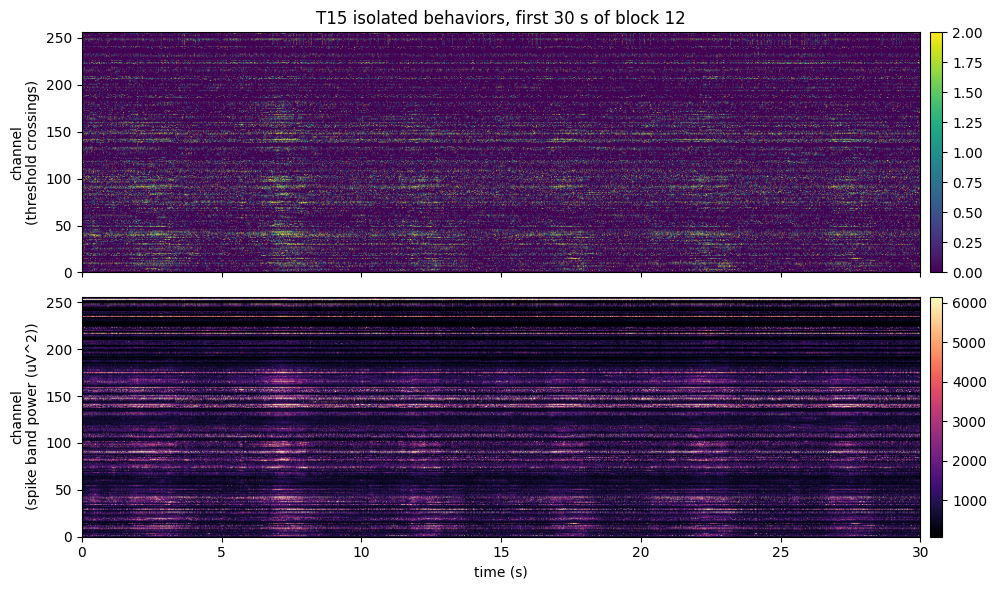

In [5]:
meta = utils.load_meta(str(F_RAW))
rate = utils.rate_hz(meta)
first_block = utils.block_segments(F_RAW)[0]

tx = utils.get_neural_stream(
    F_RAW, "threshold_crossings", first_block.start_bin, first_block.stop_bin
)
sp = utils.get_neural_stream(
    F_RAW, "spike_band_power", first_block.start_bin, first_block.stop_bin
)

print(
    f"bin size {utils.bin_size_ms(meta)} ms, {rate:.0f} Hz | arrays: {utils.array_names(F_RAW)}"
)
print(
    f"threshold_crossings {tx.shape}  range [{tx.min():.0f}, {tx.max():.0f}] counts per bin"
)
print(f"spike_band_power    {sp.shape}  range [{sp.min():.0f}, {sp.max():.0f}] uV^2")

# first 30 s of both streams
n_show = int(30 * rate)
panels = [
    (tx[:, :n_show], "threshold crossings", "viridis"),
    (sp[:, :n_show], "spike band power (uV^2)", "magma"),
]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, (values, label, cmap) in zip(axes, panels):
    im = ax.imshow(
        values,
        aspect="auto",
        origin="lower",
        cmap=cmap,
        vmin=np.percentile(values, 2),
        vmax=np.percentile(values, 98),
        extent=[0, 30, 0, values.shape[0]],
    )
    ax.set_ylabel(f"channel\n({label})")
    fig.colorbar(im, ax=ax, pad=0.01)
axes[-1].set_xlabel("time (s)")
axes[0].set_title(f"T15 isolated behaviors, first 30 s of block {first_block.block}")
plt.tight_layout()
plt.show()

## 4. Blocks

The neural activity between blocks was not recorded, so a block is the largest continuous span and the Study emits one timeline per block. `utils.block_segments` finds them in two ways:

- `blockNum`: the 29 word, sentence and counting files label every bin with its block.
- `recovered`: the 12 `seqRecall` files have no `blockNum`. Their block stops are listed in `utils.RECOVERED_SEQ_BLOCK_STOPS`, and their block ids are positions in the file.

In [6]:
examples = {
    "T15 isolated (blockNum)": F_RAW,
    "T12 seqRecallUninstructedSingleArrow (recovered)": F_TAGGED,
}
for label, path in examples.items():
    print(label)
    display(block_table(path).head(4))

T15 isolated (blockNum)


,block,start_bin,stop_bin,source,n_bins
0,12,0,39998,blockNum,39998
1,19,39998,79997,blockNum,39999
2,9,79997,119997,blockNum,40000
3,17,119997,159989,blockNum,39992


T12 seqRecallUninstructedSingleArrow (recovered)


,block,start_bin,stop_bin,source,n_bins
0,1,0,13271,recovered,13271
1,2,13271,26543,recovered,13272
2,3,26543,39801,recovered,13258


The recovered stops come from the block-wise mean subtraction of the `seqRecall` files. Each block of the float `spikePow` was centred on its own, so the cumulative sum of every channel returns to about zero where a block ends. The score below is the RMS of those sums over channels. `utils.recover_block_stops` finds its minima offline, restarting the sum at each one, and the result is checked in. The trial table plays no part in the recovery, yet every recovered block starts exactly where a trial's delay starts.

recovered stops: [13271, 26543, 39801]


recomputed     : [13271, 26543, 39801]
block starts that are a trial's delay start: [True, True, True]


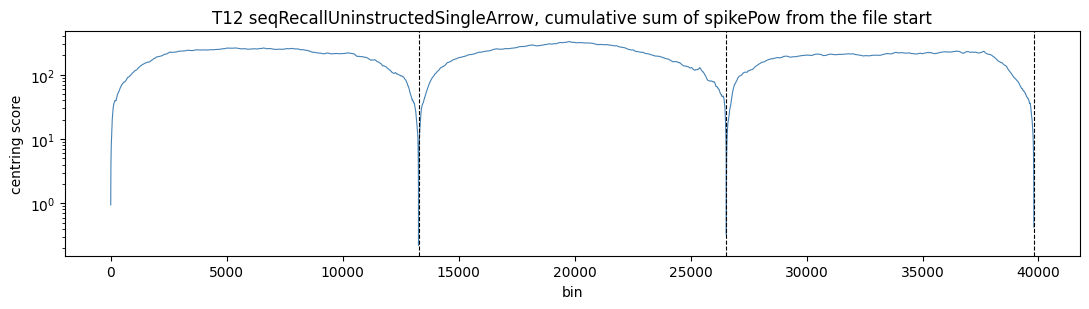

In [7]:
score = centring_score(F_TAGGED)
recovered = block_table(F_TAGGED)
delay_starts = set(utils.get_trials(F_TAGGED).delay_start_bin)

print("recovered stops:", recovered.stop_bin.tolist())
print("recomputed     :", list(utils.recover_block_stops(F_TAGGED)))
print(
    "block starts that are a trial's delay start:",
    [start in delay_starts for start in recovered.start_bin],
)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.semilogy(score, color="steelblue", lw=0.8)
for stop in recovered.stop_bin:
    ax.axvline(stop, color="k", ls="--", lw=0.8)
ax.set(
    xlabel="bin",
    ylabel="centring score",
    title="T12 seqRecallUninstructedSingleArrow, cumulative sum of spikePow from the file start",
)
plt.tight_layout()
plt.show()

## 5. Trials and cues

`utils.get_trials` parses the per-trial table of a file. In the word-cue families it resolves the cued **word** (one of seven) and the **behavior** the participant performed. Active trials have a *delay* period (cue on screen) and a *go* period (execution). The isolated **listening** and **reading** blocks, and T12's interleaved listening trials, are passive: the word is presented over the source's delay epoch and the source's go epoch is the intertrial interval (`passive=True`).

The figure shows the first 40 s of an attempted-speech block and of a listening block, with time counted from the block start.

trials per behavior and task_condition:


task_condition,attempted,imagined,listening,mimed,na,read
behavior,,,,,,
attempted,140,0,0,0,0,0
imagined_auditory,0,210,0,0,0,0
imagined_listening,0,210,0,0,0,0
imagined_motor,0,210,0,0,0,0
listening,0,0,140,0,0,0
mimed,0,0,0,140,0,0
reading,0,0,0,0,0,140
rest,0,0,0,0,170,0


,trial_id,block,word,behavior,passive,delay_start_time,delay_duration,go_start_time,go_duration
0,0,12,though,attempted,False,0.00,1.49,1.49,3.01
1,1,12,ban,attempted,False,5.00,1.50,6.50,3.01
2,2,12,though,attempted,False,10.00,1.50,11.50,3.02
3,3,12,though,attempted,False,15.01,1.50,16.51,3.01
4,4,12,ban,attempted,False,20.01,1.50,21.51,3.02


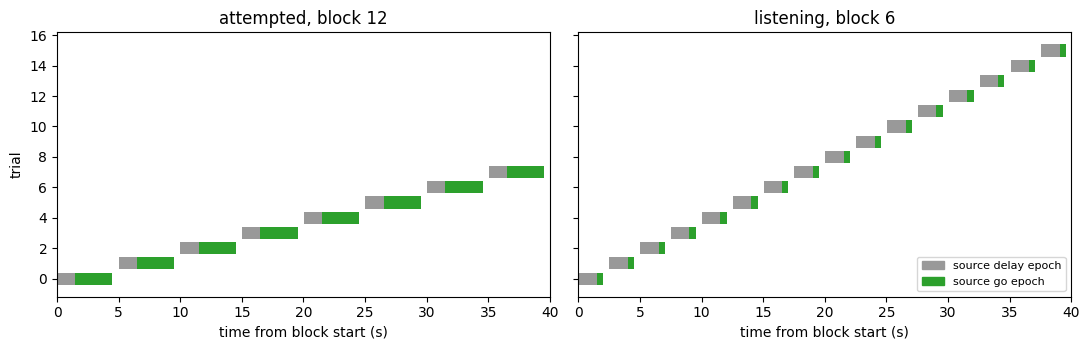

In [8]:
trials = utils.get_trials(F_RAW, meta)

print("trials per behavior and task_condition:")
display(pd.crosstab(trials.behavior, trials.task_condition))

columns = [
    "trial_id",
    "block",
    "word",
    "behavior",
    "passive",
    "delay_start_time",
    "delay_duration",
    "go_start_time",
    "go_duration",
]
display(trials[columns].head(5))

# source delay and go epochs in one active and one passive block
SHOW_S = 40.0
segments = {seg.block: seg for seg in utils.block_segments(F_RAW)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, behavior in zip(axes, ["attempted", "listening"]):
    block_id = trials[trials.behavior == behavior].block.iloc[0]
    block_start = segments[block_id].start_bin / rate
    shown = trials[trials.block == block_id].reset_index(drop=True)
    shown = shown[shown.go_start_time - block_start < SHOW_S]
    for k, row in enumerate(shown.itertuples()):
        ax.barh(
            k,
            row.delay_duration,
            left=row.delay_start_time - block_start,
            color="0.6",
            height=0.8,
        )
        ax.barh(
            k,
            row.go_duration,
            left=row.go_start_time - block_start,
            color="tab:green",
            height=0.8,
        )
    ax.set(
        xlabel="time from block start (s)",
        title=f"{behavior}, block {block_id}",
        xlim=(0, SHOW_S),
    )
axes[0].set_ylabel("trial")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ("0.6", "tab:green")]
axes[1].legend(
    handles, ["source delay epoch", "source go epoch"], fontsize=8, loc="lower right"
)
plt.tight_layout()
plt.show()

## 6. Cue vocabularies of the other families

The target differs by family: **sentences** (`sentenceData`, `chittychittybangbang`), **counts** (`conjunctiveCounting`) and **direction sequences** (`seqRecall*`, given as arrow glyphs or direction words). The cue index of a sequence file points into that file's own `cueList`, so the cue text is the key to compare across files.

In [9]:
f_sentence = DATA / "sentenceData/t15.2024.12.15_imagined_125kwords.mat"
f_counting = DATA / "conjunctiveCounting/t16.2024.12.18_conjunctive_counting.mat"
f_sequence = (
    DATA
    / "seqRecallUninstructed3ElementArrow/t12.2023.05.16_binnedTX_spikePow_20ms_joystickSeq.mat"
)

print("sentenceData, 125k-word vocabulary:")
for text in utils.get_trials(f_sentence).sentence_text.head(4):
    print("   ", repr(text))

print(
    "\nconjunctiveCounting, targets per trial:",
    list(utils.get_trials(f_counting).num_targets[:10]),
)

sequence_trials = utils.get_trials(f_sequence)
print(
    "\nseqRecall 3-element arrows, cues:", list(sequence_trials.cue_text.unique()[:8])
)
print(
    "action:",
    set(sequence_trials.action_kind),
    "| delay strategy:",
    set(sequence_trials.strategy),
)

sentenceData, 125k-word vocabulary:
    'I can sketch something for you to look at.'
    "We didn't have anyone in town that was our family."
    "It's a shame."
    'I mean what was it for?'

conjunctiveCounting, targets per trial: [11, 20, 12, 11, 13, 20, 12, 18, 16, 19]

seqRecall 3-element arrows, cues: ['← ← ↓', '→ → ←', '← → ←', '→ ↑ ↑', '→ ↓ →', '← ← →', '← ↑ ←', '→ ↓ ←']
action: {'joystick'} | delay strategy: {'uninstructed'}


## 7. Word-aligned activity

The threshold-crossing rate of one channel, aligned to the go cue and averaged over the ten trials of each word, in one T15 **attempted speech** block (compare Figure 1D of the paper).

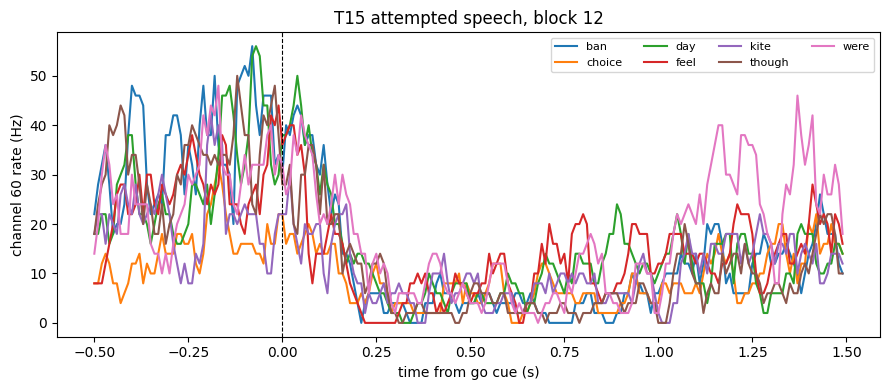

In [10]:
CHANNEL = 60  # a ventral_6v channel
PRE_S = 0.5
POST_S = 1.5

attempted = trials[trials.behavior == "attempted"]
block_id = attempted.block.iloc[0]
attempted = attempted[attempted.block == block_id]
segment = next(seg for seg in utils.block_segments(F_RAW) if seg.block == block_id)
block_tx = utils.get_neural_stream(
    F_RAW, "threshold_crossings", segment.start_bin, segment.stop_bin
)

pre = int(PRE_S * rate)
post = int(POST_S * rate)
time_axis = np.arange(-pre, post) / rate
kernel = np.ones(5) / 5

fig, ax = plt.subplots(figsize=(9, 4))
for word in utils.WORDS:
    snippets = []
    for row in attempted[attempted.word == word].itertuples():
        go = row.go_start_bin - segment.start_bin
        snippets.append(block_tx[CHANNEL, go - pre : go + post])
    mean_rate = np.mean(snippets, axis=0) * rate
    ax.plot(time_axis, np.convolve(mean_rate, kernel, "same"), label=word, lw=1.5)
ax.axvline(0, color="k", ls="--", lw=0.8)
ax.set(
    xlabel="time from go cue (s)",
    ylabel=f"channel {CHANNEL} rate (Hz)",
    title=f"T15 attempted speech, block {block_id}",
)
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

## 8. Raw and mean-subtracted files

The word, sentence and counting families ship **raw** features: non-negative integer counts and positive power. The `seqRecall` families ship **block-wise mean-subtracted** features, so both streams carry negatives and average to zero. T16's are `float64`, T12's are rounded to `int8`.

Three T12 `seqRecall` files store their `int8` values under a `uint8` class tag, so a plain read turns every negative into a value near 255. `utils` reads those bytes as `int8` (`utils.reinterpreted_uint8`), which restores the centred distribution of the sibling files. `utils` also checks every stream against its declared regime on load and raises on a mismatch.

stored class of the tagged file: uint8 | read as int8: True
raw      min / mean / max: 0.0 / 0.187 / 7.0
centred  min / mean / max: -1.9 / -0.000 / 12.4
tagged   min / mean / max: -7.0 / 0.082 / 12.0


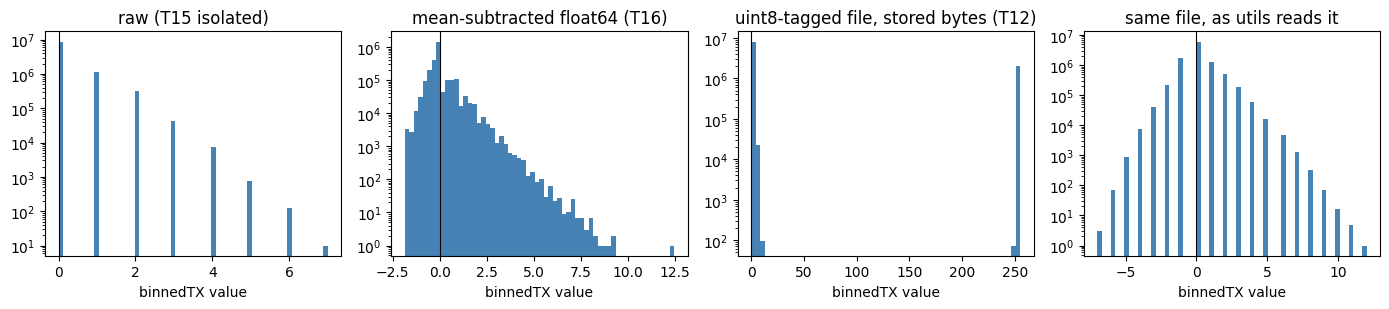

In [11]:
raw_counts = tx
centred_counts = utils.get_neural_stream(F_CENTRED, "threshold_crossings")
stored_bytes = sio.loadmat(str(F_TAGGED), variable_names=["binnedTX"])["binnedTX"]
tagged_counts = utils.get_neural_stream(F_TAGGED, "threshold_crossings")

print(
    "stored class of the tagged file:",
    utils.stored_dtype(F_TAGGED, "binnedTX"),
    "| read as int8:",
    utils.reinterpreted_uint8(F_TAGGED),
)
print(
    f"raw      min / mean / max: {raw_counts.min():.1f} / {raw_counts.mean():.3f} / {raw_counts.max():.1f}"
)
print(
    f"centred  min / mean / max: {centred_counts.min():.1f} / {centred_counts.mean():.3f} / {centred_counts.max():.1f}"
)
print(
    f"tagged   min / mean / max: {tagged_counts.min():.1f} / {tagged_counts.mean():.3f} / {tagged_counts.max():.1f}"
)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
value_histogram(axes[0], raw_counts, "raw (T15 isolated)")
value_histogram(axes[1], centred_counts, "mean-subtracted float64 (T16)")
value_histogram(axes[2], stored_bytes, "uint8-tagged file, stored bytes (T12)")
value_histogram(axes[3], tagged_counts, "same file, as utils reads it")
plt.tight_layout()
plt.show()

One T12 interleaved file (`t12.2024.04.11`) stores a byte-for-byte copy of `binnedTX` as `spikePow`. `utils.band_power_invalid_reason` reports it, and the Study emits that file's `BandPower` rows with `valid=False`.

In [12]:
copied = sio.loadmat(str(F_COPIED), variable_names=["binnedTX", "spikePow"])
print(
    "spikePow identical to binnedTX:",
    np.array_equal(copied["binnedTX"], copied["spikePow"]),
)
print("reason:", utils.band_power_invalid_reason(F_COPIED))

spikePow identical to binnedTX: True
reason: spikePow is stored as uint8 and is a byte-identical copy of binnedTX


## 9. Channel layout of the 256-column T12 files

T12 has four arrays: two in area 6v (`ventral_6v`, `dorsal_6v`, labelled `i6v` and `s6v` in the files) and two in area 44 (`ventral_44`, `dorsal_44`). The twelve word and sentence files store the 6v pair only (128 columns). The seven `seqRecall` files and the four December 2024 files store all four (256 columns), but the in-file labels do not say so: the `seqRecall` files list two arrays, and the December 2024 files call columns 64-255 `M1`, `55b`, `s6v`. The Study therefore takes the layout from `utils.ARRAY_LAYOUTS`, never from the file.

The channel correlations of a 256-column `seqRecall` file show the structure: columns 128-255 are real recordings, and the two pairs (0-127 and 128-255) are nearly uncorrelated with each other, as expected from arrays in two different gyri.

in-file labels: ['i6v', 's6v']
Study layout  : [('ventral_6v', 0, 63), ('dorsal_6v', 64, 127), ('ventral_44', 128, 191), ('dorsal_44', 192, 255)]


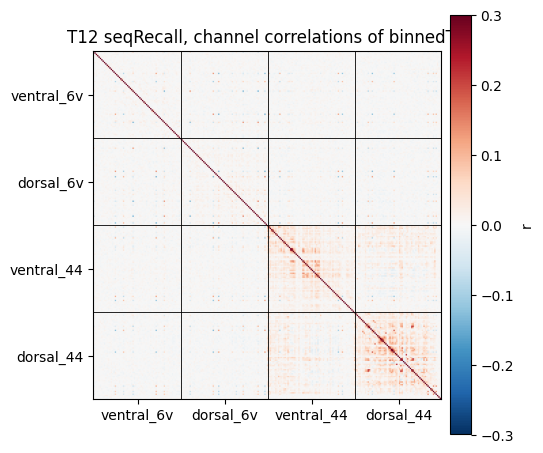

In [13]:
tagged_meta = utils.load_meta(str(F_TAGGED))
print("in-file labels:", utils.region_labels(tagged_meta))
print(
    "Study layout  :",
    [
        (name, columns.start, columns.stop - 1)
        for name, columns in utils.array_layout(F_TAGGED)
    ],
)

correlation = np.corrcoef(tagged_counts)
edges = [columns.start for _, columns in utils.array_layout(F_TAGGED)]
centers = [columns.start + 32 for _, columns in utils.array_layout(F_TAGGED)]

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(correlation, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
for edge in edges[1:]:
    ax.axhline(edge, color="k", lw=0.6)
    ax.axvline(edge, color="k", lw=0.6)
ax.set(
    xticks=centers,
    yticks=centers,
    xticklabels=utils.array_names(F_TAGGED),
    yticklabels=utils.array_names(F_TAGGED),
)
ax.set_title("T12 seqRecall, channel correlations of binnedTX")
fig.colorbar(im, ax=ax, label="r", pad=0.02)
plt.tight_layout()
plt.show()

## 10. The T16 `seqRecall` files

The five T16 `seqRecall` files store `binSize=20`, but `utils` reads them at **40 ms**. Every block starts 50 bins before its first go cue, ends 100 bins after its last one and repeats every 175-176 bins, which at 40 ms is the 2 s delay, 4 s go period and 1 s gap of the paper's Table S4. This is a curation inference, not a correction confirmed by the authors (see the README Notes).

The stored epochs of these files are the authors' analysis windows, 100 bins before and 150 bins after each go cue, so consecutive trials overlap. `utils.get_trials` places the Table S4 task periods instead: the 50 bins before and the 100 bins after each go cue.

stored binSize: 20 ms | used: 40 ms
go-to-go cycle (bins): [np.int64(175), np.int64(176)]


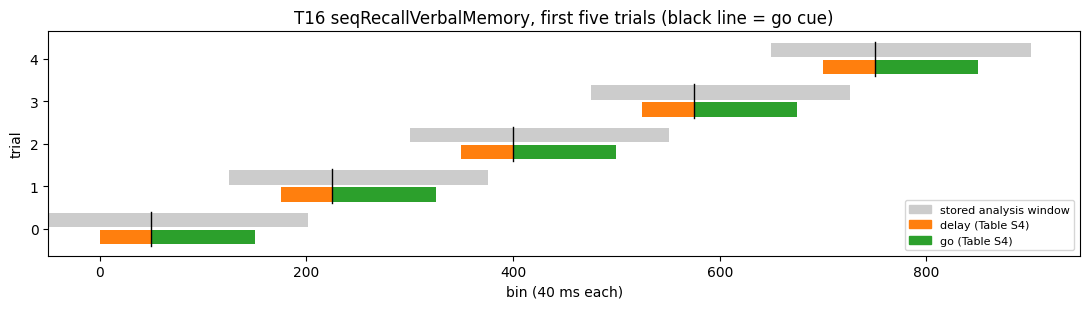

In [14]:
seq_meta = utils.load_meta(str(F_T16_SEQ))
print(
    "stored binSize:",
    seq_meta["binSizeStored"],
    "ms | used:",
    utils.bin_size_ms(seq_meta),
    "ms",
)

stored = stored_epochs(F_T16_SEQ).head(5)
placed = utils.get_trials(F_T16_SEQ, seq_meta).head(5)
print(
    "go-to-go cycle (bins):",
    sorted(set(np.diff(stored_epochs(F_T16_SEQ).go_start.to_numpy()[:40]))),
)

fig, ax = plt.subplots(figsize=(11, 3.2))
for k in range(len(stored)):
    window = stored.iloc[k]
    trial = placed.iloc[k]
    ax.barh(
        k + 0.2,
        window.go_stop - window.delay_start,
        left=window.delay_start,
        color="0.8",
        height=0.35,
    )
    ax.barh(
        k - 0.2,
        trial.delay_stop_bin - trial.delay_start_bin,
        left=trial.delay_start_bin,
        color="tab:orange",
        height=0.35,
    )
    ax.barh(
        k - 0.2,
        trial.go_stop_bin - trial.go_start_bin,
        left=trial.go_start_bin,
        color="tab:green",
        height=0.35,
    )
    ax.plot([window.go_start, window.go_start], [k - 0.4, k + 0.4], color="k", lw=1)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=c) for c in ("0.8", "tab:orange", "tab:green")
]
ax.legend(
    handles,
    ["stored analysis window", "delay (Table S4)", "go (Table S4)"],
    fontsize=8,
    loc="lower right",
)
ax.set(
    xlabel="bin (40 ms each)",
    ylabel="trial",
    yticks=range(len(stored)),
    title="T16 seqRecallVerbalMemory, first five trials (black line = go cue)",
)
plt.tight_layout()
plt.show()

## 11. Not in the deposit

The paper describes more than the deposit holds. Missing from every file:

- the joystick and stylus trajectories of the T12 sequence tasks, and whether each count of the counting task was correct.
- the audio cue waveforms, the microphone audio and the contents of the counting grids.
- the prompted verbal and autobiographical thought data of Figure S5 (`t15.2024.12.15`, `t16.2024.12.18`).
- the earlier sentence sessions that trained the real-time decoders (Table S7), and the diagnostic or rest block that opened every session.

## Summary

- 69 `.mat` files, 41 read by the Study, over 11 task types and four participants. Each file concatenates the blocks of one task on one day, and a block is the continuous unit (243 in total).
- Two neural streams per file, `binnedTX` and `spikePow`, with per-trial delay and go epochs over cued words, sentences, counts or direction sequences. Passive listening and reading trials hold the word in the delay epoch.
- Bin size, stored width, block labelling and normalization vary by file. The word, sentence and counting families are raw, the `seqRecall` families are block-wise mean-subtracted.
- Source quirks handled in `utils.py`: three `uint8`-tagged T12 files read as `int8`, one copied band-power matrix flagged invalid, the T12 array layout taken from `utils.ARRAY_LAYOUTS`, and the T16 `seqRecall` files read at 40 ms with Table S4 task periods.

Next: [`02_explore_study.ipynb`](02_explore_study.ipynb) builds the neuralset `Study` over these files.